Nikwe T 22309434 Supplementary exam

# Historical Crime Hotspot Analysis: Ekurhuleni, Gauteng

**Project purpose:** Explore historical police-reported crime patterns in Ekurhuleni, build and evaluate a simple hotspot-classification model, and add municipal demographic context.

**Datasets**
1. **SAPS Annual Crime Records (2005/06–2025/26)** — station-level annual crime counts, municipality and district names, and station coordinates. Source: [DataFirst, University of Cape Town](https://www.datafirst.uct.ac.za/dataportal/index.php/catalog/1012).
### Why this dataset was selected

This makes it particularly suitable for the examination problem because the analysis requires both geographic and temporal investigation of violence in Ekurhuleni. The dataset contains police-station names, municipality information, longitude, latitude, financial year and multiple recorded crime categories relevant to the analysis, including rape, assault, murder, attempted murder and kidnapping.

The long historical period also provides repeated observations for Ekurhuleni police stations, making it possible to investigate temporal patterns, construct historical features and develop a hotspot classification model rather than relying on a single snapshot of crime.

Access to the downloadable version of this dataset requires registration on the DataFirst portal due to the sensitivity of the information.##How to access the data
you press the link above and press "Get Micro-data" and put The name,the name of the institution along with your email.A verification link will be sent on email.
### Limitations

The dataset represents police-recorded crime rather than the complete prevalence of violence. Under-reporting, changes in reporting behaviour, policing practices and administrative changes can influence the recorded counts.

The dataset is also not consistently disaggregated by victim gender. Therefore, selected violent-crime categories are used as public-safety indicators relevant to women's safety rather than being presented as offences committed exclusively against women.

Raw crime counts may also be influenced by differences in population and exposure between police precincts.There was a neccesity to register before getting the dataset

2. **Census 2022 municipal indicators** — municipal population and demographic indicators, including 2011 and 2022 estimates. File: `person-indicators-muni.csv`. Source: [public dataset repository](https://github.com/afrith/census-2022-muni-stats).

**Research questions**
- Which recorded crime categories and years stand out in Ekurhuleni?
- Which police stations have higher recorded violence counts or more hotspot years?
- Can previous-year crime information help classify whether a station-year is a high-violence hotspot?

**Important geographic limitation:** The selected second dataset is municipal demographic data, not police-station boundary polygons. This notebook filters to Ekurhuleni using the SAPS municipality field, maps station coordinates, and joins municipal indicators by municipality name. It does **not** claim to perform a station-boundary polygon match. The population figures describe the whole municipality, not individual station catchment areas.

**Methodological principle:** Missing crime counts are not automatically replaced with zero. The hotspot model predicts a station-year label using information from the previous observed year, to reduce target leakage. Data are split chronologically into 70% training, 15% validation, and 15% final testing by year.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
from pathlib import Path

crime = pd.read_csv('/content/drive/MyDrive/EkurhuleniSafety/sapacr-2005-2026-v1.5.csv')
population = pd.read_csv('/content/drive/MyDrive/EkurhuleniSafety/person-indicators-muni.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Import the libraries

Pandas handles tabular data, Matplotlib and Seaborn create charts, and Scikit-learn supplies preprocessing pipelines and classification metrics. We use a fixed random seed where randomness is involved so results can be reproduced.

In [6]:
import re
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score,
    f1_score, balanced_accuracy_score, average_precision_score, roc_auc_score,
    matthews_corrcoef, classification_report
)

RANDOM_STATE = 42
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

## 3. Load both datasets and inspect their structure

The first inspection confirms that the files loaded and shows their dimensions and column names. This is useful before changing anything because the two datasets were produced by different sources and may use different naming conventions.

In [7]:
print('SAPS crime dataset shape:', crime.shape)
print('Municipal indicators dataset shape:', population.shape)

display(crime.head())
display(population.head())

print('Crime columns:')
print(crime.columns.tolist())

print('\nPopulation columns:')
print(population.columns.tolist())

SAPS crime dataset shape: (24316, 38)
Municipal indicators dataset shape: (213, 18)


,year,station,loc_mn,dc_mn,longitude,latitude,dui,drug_crime,illegal_firearms,malicious_damage,arson,bank_robbery,burglary_nonres,burglary_res,carjacking,truck_hijacking,commercial_crime,common_assault,assault_gbh,robbery_nonres,robbery_res,cash_transit_robbery,aggr_robbery,common_robbery,murder,attempted_murder,attempted_sexoff,rape,sexual_assault,police_detected_sexoff,contact_sexoff,sexual_offences,kidnapping,shoplifting,stock_theft,vehicle_theft,theft_from_vehicle,other_theft
0,2005/2006,aberdeen,dr beyers naude,sarah baartman,"23,8712379454244","-32,5967545437703",2,12,0,26,0,0,25,81,0,0,5,44,79,0,0,0,1,8,7,3,0.0,0.0,0.0,0,NaN,0,0,3,46,0,9.0,63
1,2005/2006,acornhoek,bushbuckridge,ehlanzeni,"30,9975703031244","-24,6230113831757",1,23,19,149,21,0,76,357,3,0,23,173,385,1,12,0,127,100,21,27,0.0,0.0,0.0,0,0.0,0,0,84,15,17,24.0,223
2,2005/2006,actonville,ekurhuleni,ekurhuleni,"28,3056180857924","-26,2199687974063",28,55,10,121,9,0,13,228,39,0,14,201,285,12,39,0,193,99,20,25,0.0,NaN,0.0,0,0.0,0,4,5,0,95,69.0,150
3,2005/2006,addo,sundays river valley,sarah baartman,"25,668585191722","-33,5451593189792",7,6,1,42,4,0,13,186,1,0,5,124,242,0,0,0,13,16,13,28,0.0,0.0,0.0,0,NaN,0,0,3,26,13,16.0,153
4,2005/2006,adelaide,raymond mhlaba,amathole,"26,2928437206771","-32,6717099958241",2,7,1,36,2,0,34,114,0,0,9,130,169,0,0,0,13,14,6,4,0.0,0.0,0.0,0,0.0,0,1,13,68,5,15.0,85


,prov_code,dc_code,muni_code,name,area_km2,miif_category,government_transfers_subsidies_percent,male_pop_2011,female_pop_2011,total_pop_2011,school_attendance_ages_5_to_24_2011,sex_ratio_2011,male_pop_2022,female_pop_2022,total_pop_2022,school_attendance_ages_5_to_24_2022,sex_ratio_2022,growth_rate_2011_to_2022
0,EC,BUF,BUF,Buffalo City,2752.6,METRO,19.4,371242,410610,781853,195367,90.4,461693,513562,975255,233425,89.9,2.1
1,EC,DC10,EC101,Dr Beyers Naude,28653.0,B3,37.8,38599,40693,79292,18657,94.9,47720,53281,101001,22689,89.6,2.3
2,EC,DC10,EC102,Blue Crane Route,11068.5,B3,34.9,17680,18322,36002,8036,96.5,24191,25691,49883,10653,94.2,3.2
3,EC,DC10,EC104,Makana,4376.4,B2,31.3,38175,42215,80390,18517,90.4,45885,51930,97815,22021,88.4,1.9
4,EC,DC10,EC105,Ndlambe,1839.9,B3,38.2,29035,32141,61176,12731,90.3,41327,46470,87797,17031,88.9,3.5


Crime columns:
['year', 'station', 'loc_mn', 'dc_mn', 'longitude', 'latitude', 'dui', 'drug_crime', 'illegal_firearms', 'malicious_damage', 'arson', 'bank_robbery', 'burglary_nonres', 'burglary_res', 'carjacking', 'truck_hijacking', 'commercial_crime', 'common_assault', 'assault_gbh', 'robbery_nonres', 'robbery_res', 'cash_transit_robbery', 'aggr_robbery', 'common_robbery', 'murder', 'attempted_murder', 'attempted_sexoff', 'rape', 'sexual_assault', 'police_detected_sexoff', 'contact_sexoff', 'sexual_offences', 'kidnapping', 'shoplifting', 'stock_theft', 'vehicle_theft', 'theft_from_vehicle', 'other_theft']

Population columns:
['prov_code', 'dc_code', 'muni_code', 'name', 'area_km2', 'miif_category', 'government_transfers_subsidies_percent', 'male_pop_2011', 'female_pop_2011', 'total_pop_2011', 'school_attendance_ages_5_to_24_2011', 'sex_ratio_2011', 'male_pop_2022', 'female_pop_2022', 'total_pop_2022', 'school_attendance_ages_5_to_24_2022', 'sex_ratio_2022', 'growth_rate_2011_to_2022'

## 4. Standardise column names

Standardisation means making column names consistent across sources. This code converts names to lowercase, replaces spaces and punctuation with underscores, and removes repeated underscores. We keep the original DataFrames unchanged and work on copies.

In [8]:
def standardise_columns(df):
    df = df.copy()
    df.columns = (
        pd.Index(df.columns)
        .str.strip()
        .str.lower()
        .str.replace(r'[^a-z0-9]+', '_', regex=True)
        .str.strip('_')
    )
    return df

crime = standardise_columns(crime)
population = standardise_columns(population)

print('Standardised crime columns:', crime.columns.tolist())
print('Standardised population columns:', population.columns.tolist())

Standardised crime columns: ['year', 'station', 'loc_mn', 'dc_mn', 'longitude', 'latitude', 'dui', 'drug_crime', 'illegal_firearms', 'malicious_damage', 'arson', 'bank_robbery', 'burglary_nonres', 'burglary_res', 'carjacking', 'truck_hijacking', 'commercial_crime', 'common_assault', 'assault_gbh', 'robbery_nonres', 'robbery_res', 'cash_transit_robbery', 'aggr_robbery', 'common_robbery', 'murder', 'attempted_murder', 'attempted_sexoff', 'rape', 'sexual_assault', 'police_detected_sexoff', 'contact_sexoff', 'sexual_offences', 'kidnapping', 'shoplifting', 'stock_theft', 'vehicle_theft', 'theft_from_vehicle', 'other_theft']
Standardised population columns: ['prov_code', 'dc_code', 'muni_code', 'name', 'area_km2', 'miif_category', 'government_transfers_subsidies_percent', 'male_pop_2011', 'female_pop_2011', 'total_pop_2011', 'school_attendance_ages_5_to_24_2011', 'sex_ratio_2011', 'male_pop_2022', 'female_pop_2022', 'total_pop_2022', 'school_attendance_ages_5_to_24_2022', 'sex_ratio_2022', '

## 5. Standardise text values and create matching keys

Station and municipality names can differ in capitalisation, punctuation, or extra spaces. The helper below makes a matching key by lowercasing text and replacing punctuation with spaces. It does not use fuzzy matching, because automatically guessing that two different station names are the same could create incorrect joins.

In [9]:
def normalise_text(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip().lower()
    value = re.sub(r'[^a-z0-9]+', ' ', value)
    value = re.sub(r'\s+', ' ', value).strip()
    return value

# Check required source columns before continuing.
required_crime = {'year', 'station', 'loc_mn', 'longitude', 'latitude'}
required_population = {'name', 'muni_code', 'total_pop_2022', 'female_pop_2022'}
assert required_crime.issubset(crime.columns), f'Missing crime columns: {required_crime - set(crime.columns)}'
assert required_population.issubset(population.columns), f'Missing population columns: {required_population - set(population.columns)}'

crime['station_key'] = crime['station'].map(normalise_text)
crime['municipality_key'] = crime['loc_mn'].map(normalise_text)
population['municipality_key'] = population['name'].map(normalise_text)

display(crime[['station', 'station_key', 'loc_mn', 'municipality_key']].head())
display(population[['name', 'municipality_key', 'muni_code']].head())

,station,station_key,loc_mn,municipality_key
0,aberdeen,aberdeen,dr beyers naude,dr beyers naude
1,acornhoek,acornhoek,bushbuckridge,bushbuckridge
2,actonville,actonville,ekurhuleni,ekurhuleni
3,addo,addo,sundays river valley,sundays river valley
4,adelaide,adelaide,raymond mhlaba,raymond mhlaba


,name,municipality_key,muni_code
0,Buffalo City,buffalo city,BUF
1,Dr Beyers Naude,dr beyers naude,EC101
2,Blue Crane Route,blue crane route,EC102
3,Makana,makana,EC104
4,Ndlambe,ndlambe,EC105


## 6. Inspect missing values

Missingness is counted and shown as both a table and a chart. A blank crime count is not automatically a zero: it could mean unavailable or unreported information. The model pipeline will handle missing predictor values later, while the target outcome will only be calculated when all selected violence components are present.

,missing_count,missing_percent
rape,443,1.82
contact_sexoff,388,1.60
dc_mn,378,1.55
loc_mn,378,1.55
latitude,378,1.55
municipality_key,378,1.55
longitude,378,1.55
sexual_assault,252,1.04
attempted_sexoff,123,0.51
dui,0,0.00


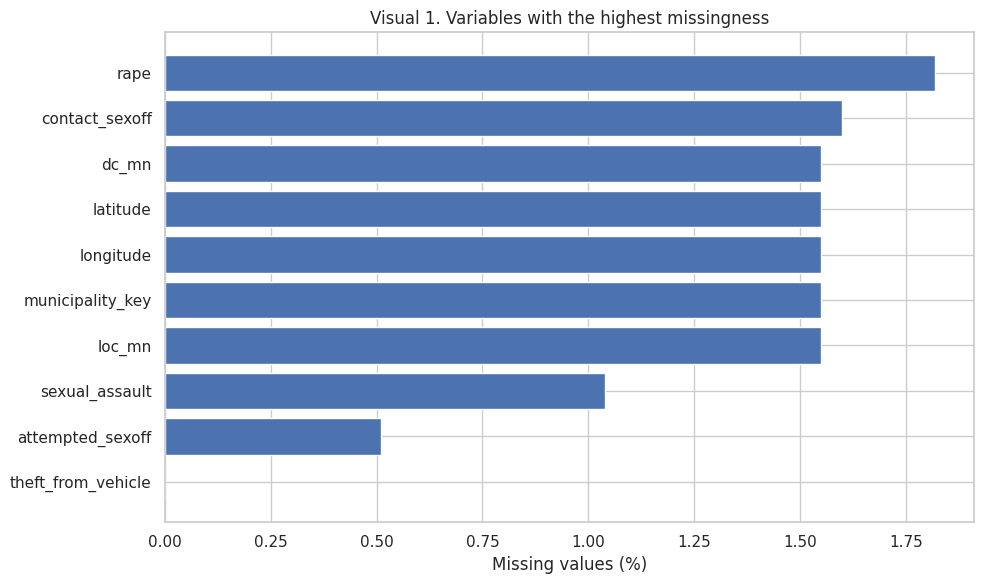

In [10]:
missing_summary = (
    pd.DataFrame({
        'missing_count': crime.isna().sum(),
        'missing_percent': (crime.isna().mean() * 100).round(2)
    })
    .sort_values('missing_percent', ascending=False)
)
display(missing_summary.head(20))

missing_plot = missing_summary[missing_summary['missing_count'] > 0].head(15).sort_values('missing_percent')
plt.figure(figsize=(10, 6))
plt.barh(missing_plot.index, missing_plot['missing_percent'])
plt.xlabel('Missing values (%)')
plt.title('Visual 1. Variables with the highest missingness')
plt.tight_layout()
plt.show()

## 7. Check duplicates and station-name consistency

We check exact duplicate rows and duplicate station-year records. Station-year duplicates should be investigated before modelling because they may count the same station and year more than once. We also list raw station names that become the same normalised key; these are candidates for manual review, not automatic proof of an error.

In [11]:
exact_duplicates = int(crime.duplicated().sum())
station_year_duplicates = int(crime.duplicated(subset=['station_key', 'year'], keep=False).sum())

print('Exact duplicate rows:', exact_duplicates)
print('Rows involved in duplicate station-year keys:', station_year_duplicates)

name_variants = (
    crime.dropna(subset=['station_key', 'station'])
    .groupby('station_key')['station']
    .agg(lambda x: sorted(set(map(str, x))))
)
name_variants = name_variants[name_variants.map(len) > 1]
print('Normalised station keys with multiple raw name variants:', len(name_variants))
display(name_variants.rename('raw_name_variants').to_frame().head(30))

# Remove only exact duplicate rows. Do not arbitrarily aggregate station-year duplicates.
crime = crime.drop_duplicates().copy()

Exact duplicate rows: 0
Rows involved in duplicate station-year keys: 0
Normalised station keys with multiple raw name variants: 0


,raw_name_variants
station_key,


## 8. Convert coordinates and crime counts to numeric values

Some SAPS coordinates use a comma as the decimal separator. We replace that separator before conversion. Crime count columns are converted to numeric values; invalid strings become missing values so they can be reviewed rather than silently interpreted as zero.

In [12]:
# Convert decimal-comma coordinates, for example '23,87' -> 23.87.
for col in ['longitude', 'latitude']:
    crime[col] = pd.to_numeric(
        crime[col].astype('string').str.replace(',', '.', regex=False),
        errors='coerce'
    )

# Treat all remaining non-ID fields as potential crime count fields.
id_columns = {
    'year', 'station', 'loc_mn', 'dc_mn', 'longitude', 'latitude',
    'station_key', 'municipality_key'
}
crime_count_cols = [c for c in crime.columns if c not in id_columns]

for col in crime_count_cols:
    crime[col] = pd.to_numeric(crime[col], errors='coerce')

print('Crime count columns detected:', len(crime_count_cols))
display(crime[crime_count_cols].describe().T.head(20))

Crime count columns detected: 32


,count,mean,std,min,25%,50%,75%,max
dui,24316.0,54.600099,104.141173,0.0,3.00,16.0,59.0,2687.0
drug_crime,24316.0,160.905083,339.806735,0.0,13.00,49.0,160.0,6571.0
illegal_firearms,24316.0,12.855280,21.979137,0.0,1.00,4.0,15.0,275.0
malicious_damage,24316.0,102.727998,139.754310,0.0,15.75,49.0,133.0,1845.0
arson,24316.0,4.267437,6.154959,0.0,0.00,2.0,6.0,81.0
bank_robbery,24316.0,0.027718,0.235221,0.0,0.00,0.0,0.0,9.0
burglary_nonres,24316.0,56.785244,78.269227,0.0,10.00,31.0,73.0,1009.0
burglary_res,24316.0,187.706860,235.089394,0.0,31.00,101.0,252.0,2345.0
carjacking,24316.0,13.381272,31.725330,0.0,0.00,1.0,9.0,554.0
truck_hijacking,24316.0,1.111737,3.723153,0.0,0.00,0.0,1.0,99.0


## 9. Check invalid coordinates and crime-count anomalies

For longitude and latitude in South Africa, plausible ranges are longitude from about 16 to 33 degrees east and latitude from about -35 to -22 degrees south. These broad bounds are a screening rule, not a substitute for validating every station location. Negative crime counts are invalid and are reported. We do not silently clip them to zero.

In [13]:
invalid_coordinates = (
    crime['longitude'].isna() | crime['latitude'].isna() |
    ~crime['longitude'].between(16, 33) |
    ~crime['latitude'].between(-35, -22)
)
negative_counts = crime[crime_count_cols].lt(0).any(axis=1)

print('Rows with missing/out-of-range coordinates:', int(invalid_coordinates.sum()))
print('Rows with one or more negative crime counts:', int(negative_counts.sum()))

display(crime.loc[invalid_coordinates, ['station', 'loc_mn', 'longitude', 'latitude']].head(15))
display(crime.loc[negative_counts, ['station', 'year'] + crime_count_cols[:8]].head(15))

# Flag coordinate problems for mapping; do not delete crime records just because coordinates are missing.
crime['coordinates_valid'] = ~invalid_coordinates

Rows with missing/out-of-range coordinates: 378
Rows with one or more negative crime counts: 0


,station,loc_mn,longitude,latitude
67,berlin,NaN,<NA>,<NA>
81,bityi,NaN,<NA>,<NA>
209,dingleton,NaN,<NA>,<NA>
248,elliot,NaN,<NA>,<NA>
442,katkop,NaN,<NA>,<NA>
462,king william's town,NaN,<NA>,<NA>
486,komga,NaN,<NA>,<NA>
518,lady frere,NaN,<NA>,<NA>
572,maclear,NaN,<NA>,<NA>
598,maluti,NaN,<NA>,<NA>


,station,year,dui,drug_crime,illegal_firearms,malicious_damage,arson,bank_robbery,burglary_nonres,burglary_res


## 10. Isolate the Ekurhuleni study area

The SAPS field `loc_mn` identifies the municipality. We normalise it and select Ekurhuleni records. This is a municipality-field filter, not a spatial point-in-polygon join, because our selected second dataset does not contain station boundary polygons.

In [14]:
ekurhuleni = crime.loc[crime['municipality_key'].eq('ekurhuleni')].copy()

print('Ekurhuleni rows:', len(ekurhuleni))
print('Distinct stations:', ekurhuleni['station_key'].nunique())
print('Years:', sorted(ekurhuleni['year'].dropna().astype(str).unique())[:3], '...', sorted(ekurhuleni['year'].dropna().astype(str).unique())[-3:])

if ekurhuleni.empty:
    raise ValueError('No Ekurhuleni records found. Inspect unique values in crime["loc_mn"] and adjust the municipality filter.')

display(ekurhuleni[['year', 'station', 'loc_mn', 'longitude', 'latitude']].head())

Ekurhuleni rows: 756
Distinct stations: 36
Years: ['2005/2006', '2006/2007', '2007/2008'] ... ['2023/2024', '2024/2025', '2025/2026']


,year,station,loc_mn,longitude,latitude
2,2005/2006,actonville,ekurhuleni,28.305618,-26.219969
9,2005/2006,alberton,ekurhuleni,28.13997,-26.284027
53,2005/2006,bedfordview,ekurhuleni,28.154703,-26.166956
64,2005/2006,benoni,ekurhuleni,28.334452,-26.167164
90,2005/2006,boksburg,ekurhuleni,28.259105,-26.23963


## 11. Join the municipal population dataset

The population data is joined using a normalised municipality name. The merge is many-to-one: many station-year records can relate to the one Ekurhuleni municipal record. We retain the municipality population columns as context only; we do not assign the whole municipal population to each police station or calculate station-level population rates.

In [15]:
population_for_join = population.rename(columns={'name': 'population_municipality_name'}).copy()

# This analysis is restricted to Ekurhuleni, so keep the matching Ekurhuleni municipal record only.
# This also avoids duplicate-name issues elsewhere in the national file (for example, Emalahleni).
population_for_join = population_for_join.loc[
    population_for_join['municipality_key'].eq('ekurhuleni')
].drop_duplicates(subset=['municipality_key'])

if population_for_join.empty:
    raise ValueError('Ekurhuleni was not found in the municipal population dataset.')

merged = ekurhuleni.merge(
    population_for_join,
    on='municipality_key',
    how='left',
    validate='many_to_one',
    suffixes=('_crime', '_population')
)

print('Rows before join:', len(ekurhuleni))
print('Rows after join:', len(merged))
print('Rows without matched population record:', int(merged['total_pop_2022'].isna().sum()))

display(merged[['station', 'loc_mn', 'population_municipality_name', 'total_pop_2022', 'female_pop_2022']].head())

Rows before join: 756
Rows after join: 756
Rows without matched population record: 0


,station,loc_mn,population_municipality_name,total_pop_2022,female_pop_2022
0,actonville,ekurhuleni,Ekurhuleni,4066691,1989339
1,alberton,ekurhuleni,Ekurhuleni,4066691,1989339
2,bedfordview,ekurhuleni,Ekurhuleni,4066691,1989339
3,benoni,ekurhuleni,Ekurhuleni,4066691,1989339
4,boksburg,ekurhuleni,Ekurhuleni,4066691,1989339


## 12. Create year and crime-analysis variables

The year label such as `2005/2006` is converted to a numeric starting year for sorting. The violence measure sums seven non-aggregate categories: murder, attempted murder, rape, sexual assault, common assault, assault with intent to cause grievous bodily harm, and kidnapping. We exclude the broader `sexual_offences` aggregate to avoid obvious double-counting of related sexual-offence categories.

A violence count is only calculated when every component is available. This makes the target definition consistent, but means rows with missing components are excluded from hotspot labelling and model targets.

In [16]:
ekurhuleni = merged.copy()
ekurhuleni['year'] = ekurhuleni['year'].astype('string').str.strip()
ekurhuleni['year_start'] = pd.to_numeric(
    ekurhuleni['year'].str.extract(r'^(\d{4})')[0],
    errors='coerce'
)

violence_components = [
    'murder', 'attempted_murder', 'rape', 'sexual_assault',
    'common_assault', 'assault_gbh', 'kidnapping'
]
missing_components = [c for c in violence_components if c not in ekurhuleni.columns]
assert not missing_components, f'Violence columns missing: {missing_components}'

ekurhuleni['violence_components_complete'] = ekurhuleni[violence_components].notna().all(axis=1)
ekurhuleni['violence_count'] = ekurhuleni[violence_components].sum(axis=1, min_count=len(violence_components))

print('Rows with complete violence components:', int(ekurhuleni['violence_count'].notna().sum()))
print('Rows excluded from violence target due to missing components:', int(ekurhuleni['violence_count'].isna().sum()))
display(ekurhuleni[['year', 'year_start', 'station', 'violence_count']].head())

Rows with complete violence components: 702
Rows excluded from violence target due to missing components: 54


,year,year_start,station,violence_count
0,2005/2006,2005,actonville,NaN
1,2005/2006,2005,alberton,NaN
2,2005/2006,2005,bedfordview,369.0
3,2005/2006,2005,benoni,NaN
4,2005/2006,2005,boksburg,NaN


## 13. Visual 2 — Compare recorded violence categories

This bar chart compares the sum of each selected violence category across all Ekurhuleni station-years. It is a category-level comparison, not a count of unique incidents across all categories. The chart helps identify which selected categories contribute most to the recorded violence profile.

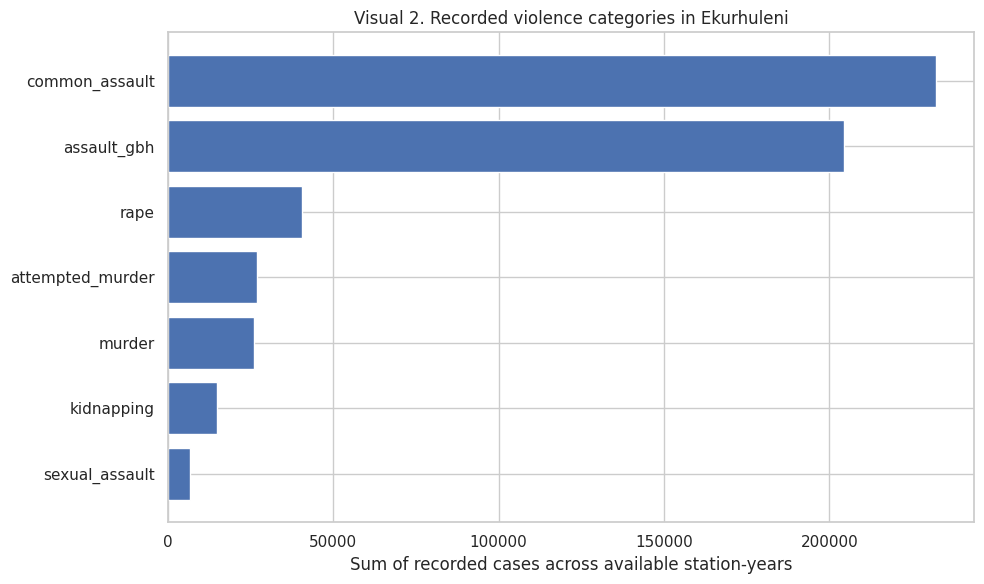

In [17]:
category_totals = ekurhuleni[violence_components].sum(skipna=True).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(category_totals.index, category_totals.values)
plt.xlabel('Sum of recorded cases across available station-years')
plt.title('Visual 2. Recorded violence categories in Ekurhuleni')
plt.tight_layout()
plt.show()

## 14. Visual 3 — Historical trend in recorded violence

We sum station-level violence counts by reporting year. This shows changes in recorded counts over time. These trends may reflect changes in crime, reporting, station boundaries, or data collection, so they should not automatically be interpreted as changes in underlying risk.

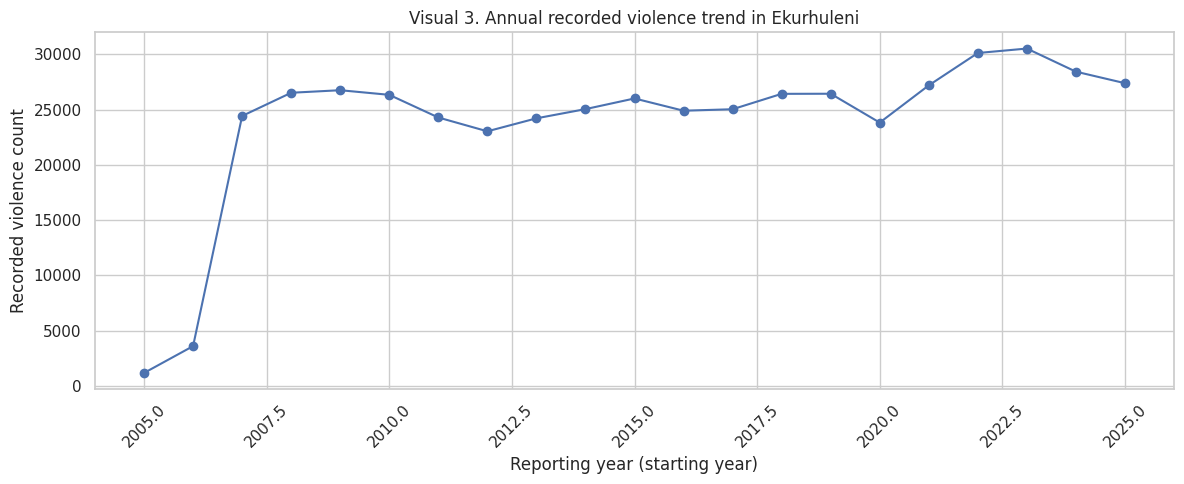

,year_start,year,violence_count
11,2016,2016/2017,24895.0
12,2017,2017/2018,25029.0
13,2018,2018/2019,26423.0
14,2019,2019/2020,26432.0
15,2020,2020/2021,23820.0
16,2021,2021/2022,27190.0
17,2022,2022/2023,30119.0
18,2023,2023/2024,30522.0
19,2024,2024/2025,28430.0
20,2025,2025/2026,27387.0


In [18]:
annual_violence = (
    ekurhuleni.groupby(['year_start', 'year'], dropna=False)['violence_count']
    .sum(min_count=1)
    .reset_index()
    .dropna(subset=['year_start'])
    .sort_values('year_start')
)

plt.figure(figsize=(12, 5))
plt.plot(annual_violence['year_start'], annual_violence['violence_count'], marker='o')
plt.xlabel('Reporting year (starting year)')
plt.ylabel('Recorded violence count')
plt.title('Visual 3. Annual recorded violence trend in Ekurhuleni')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(annual_violence.tail(10))

## 15. Visual 4 — Police stations with the highest violence counts

This chart ranks stations by their total available violence count across the study period. It helps identify stations for closer investigation. Because stations may serve populations of different sizes, this is a comparison of recorded counts, not a population-adjusted risk ranking.

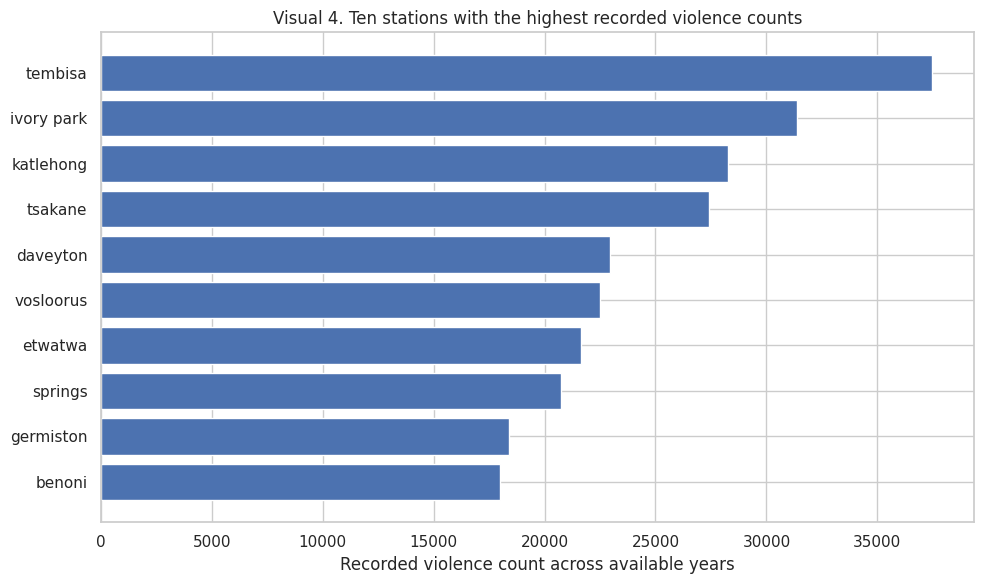

,station_key,station,violence_count
30,tembisa,tembisa,37478.0
18,ivory park,ivory park,31367.0
19,katlehong,katlehong,28274.0
33,tsakane,tsakane,27416.0
9,daveyton,daveyton,22966.0
34,vosloorus,vosloorus,22501.0
16,etwatwa,etwatwa,21645.0
29,springs,springs,20734.0
17,germiston,germiston,18377.0
3,benoni,benoni,17991.0


In [19]:
station_totals = (
    ekurhuleni.groupby(['station_key', 'station'])['violence_count']
    .sum(min_count=1)
    .reset_index()
    .sort_values('violence_count', ascending=False)
)

top_stations = station_totals.head(10).sort_values('violence_count', ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(top_stations['station'], top_stations['violence_count'])
plt.xlabel('Recorded violence count across available years')
plt.title('Visual 4. Ten stations with the highest recorded violence counts')
plt.tight_layout()
plt.show()

display(station_totals.head(10))

## 16. Visual 5 — Heatmap of station-by-year violence counts

A heatmap shows whether high or low counts are concentrated in particular station-years. We display the 12 stations with the highest total violence counts to keep labels readable. Missing values remain blank rather than being converted to zero.

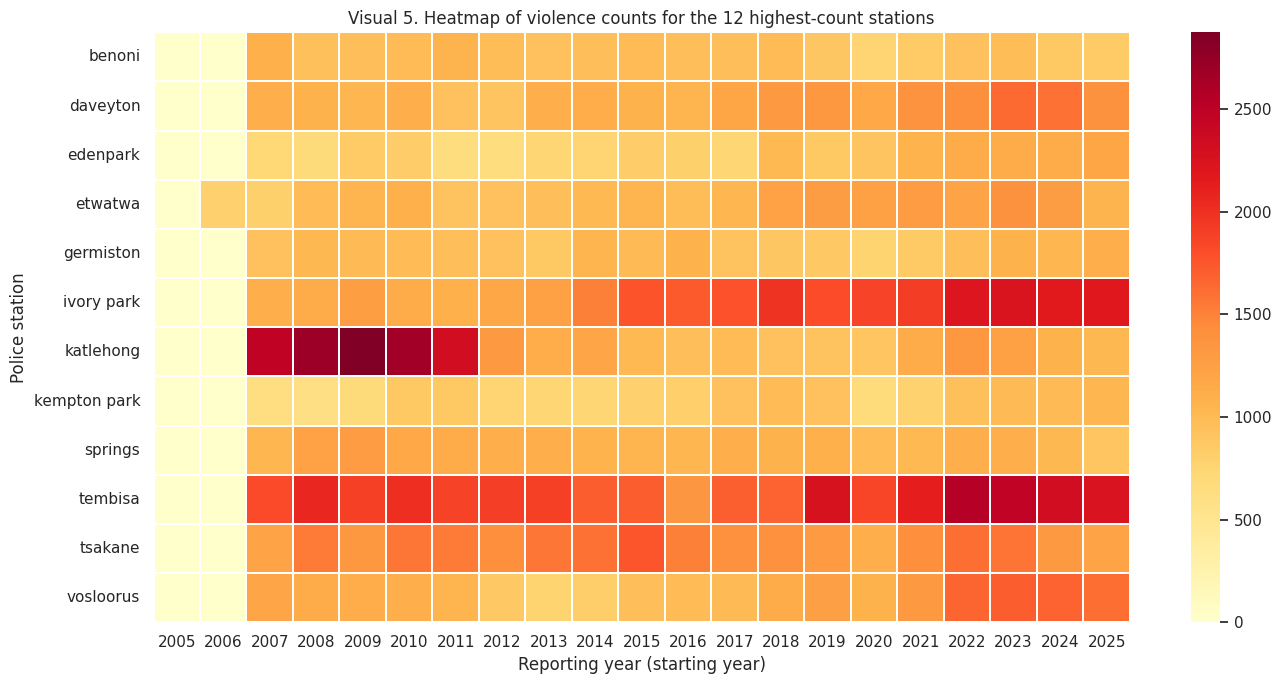

In [20]:
top12_keys = station_totals.head(12)['station_key'].tolist()
heat_data = (
    ekurhuleni[ekurhuleni['station_key'].isin(top12_keys)]
    .pivot_table(index='station', columns='year_start', values='violence_count', aggfunc='sum')
)

plt.figure(figsize=(14, 7))
sns.heatmap(heat_data, cmap='YlOrRd', linewidths=0.2)
plt.xlabel('Reporting year (starting year)')
plt.ylabel('Police station')
plt.title('Visual 5. Heatmap of violence counts for the 12 highest-count stations')
plt.tight_layout()
plt.show()

## 17. Visual 6 — Plot station coordinates

This point map plots available station coordinates within the Ekurhuleni-filtered records. It is a coordinate scatterplot, not a boundary map. The colour represents the share of observed station-years classified as hotspots using the threshold defined below. Invalid coordinates are excluded from the map but the underlying crime records remain in the dataset.

### Define the hotspot threshold

For each reporting year, a station-year is labelled a hotspot when its violence count is at or above the 75th percentile of complete station-year violence counts for that year. This relative threshold identifies the higher-count quarter of stations each year and accommodates changes in overall counts across years. It is a statistical classification rule, not an official police designation or proof of danger to individuals.

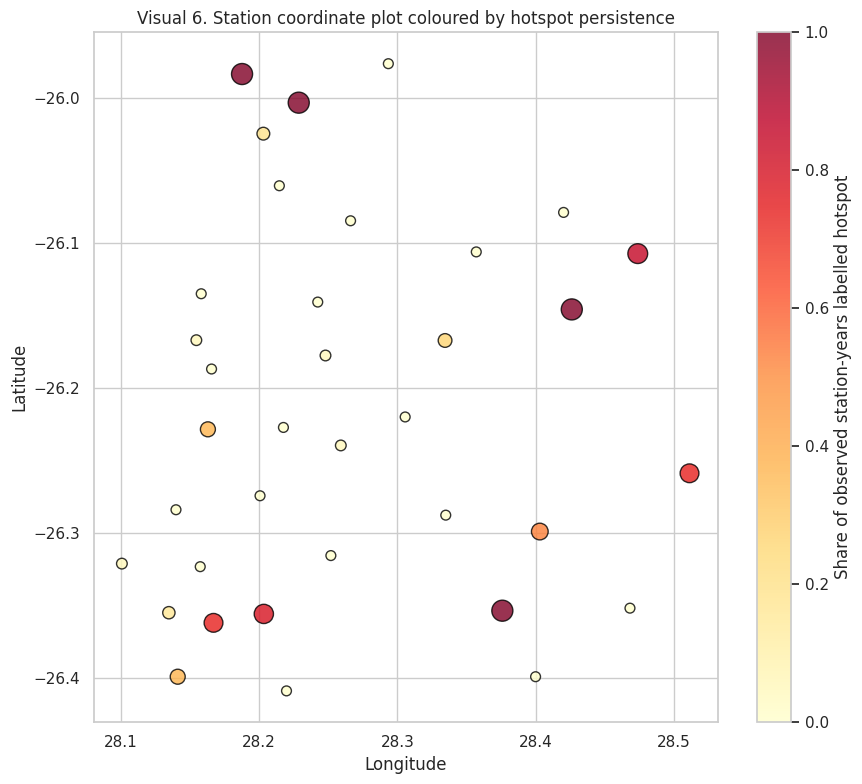

Stations plotted: 36


In [21]:
ekurhuleni['hotspot_threshold'] = (
    ekurhuleni.groupby('year_start')['violence_count']
    .transform(lambda s: s.quantile(0.75) if s.notna().any() else np.nan)
)

ekurhuleni['hotspot'] = np.where(
    ekurhuleni['violence_count'].notna() & ekurhuleni['hotspot_threshold'].notna(),
    (ekurhuleni['violence_count'] >= ekurhuleni['hotspot_threshold']).astype(int),
    np.nan
)

hotspot_share = (
    ekurhuleni.groupby('station_key')
    .agg(station=('station', 'first'), hotspot_share=('hotspot', 'mean'), years_observed=('hotspot', 'count'))
    .reset_index()
)

map_points = (
    ekurhuleni.loc[ekurhuleni['coordinates_valid']]
    .sort_values('year_start')
    .groupby('station_key')
    .agg(station=('station', 'first'), longitude=('longitude', 'median'), latitude=('latitude', 'median'))
    .reset_index()
    .merge(hotspot_share, on=['station_key', 'station'], how='left')
)

plt.figure(figsize=(9, 8))
sc = plt.scatter(
    map_points['longitude'], map_points['latitude'],
    c=map_points['hotspot_share'], s=50 + 180 * map_points['hotspot_share'].fillna(0),
    cmap='YlOrRd', alpha=0.8, edgecolor='black'
)
plt.colorbar(sc, label='Share of observed station-years labelled hotspot')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Visual 6. Station coordinate plot coloured by hotspot persistence')
plt.tight_layout()
plt.show()

print('Stations plotted:', len(map_points))

## 18. Visual 7 — Compare station-level distributions

This boxplot compares the spread of annual violence counts for the six stations with the highest total counts. The median and spread show whether a station's overall total reflects consistently high counts or a few unusually high years. Outliers are observations to investigate, not automatically errors.

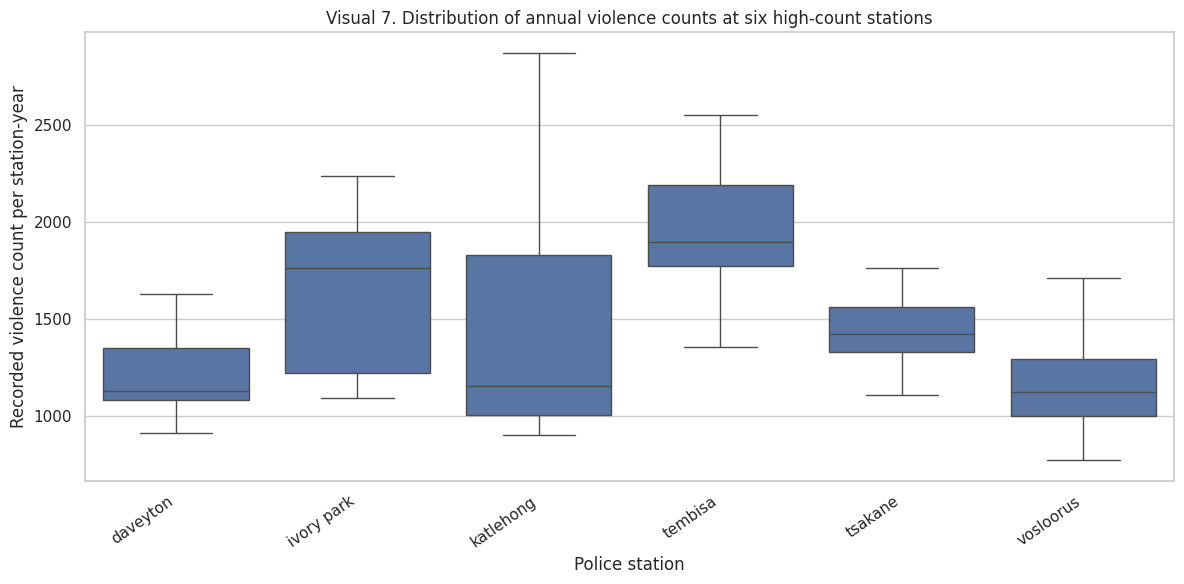

In [22]:
top6_names = station_totals.head(6)['station'].tolist()
box_data = ekurhuleni.loc[ekurhuleni['station'].isin(top6_names), ['station', 'violence_count']].dropna()

plt.figure(figsize=(12, 6))
sns.boxplot(data=box_data, x='station', y='violence_count')
plt.xlabel('Police station')
plt.ylabel('Recorded violence count per station-year')
plt.title('Visual 7. Distribution of annual violence counts at six high-count stations')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## 19. Visual 8 — Compare municipal male and female population estimates

This chart uses the single Ekurhuleni municipal record from the demographic dataset. It provides context on the size of the male and female populations in 2011 and 2022. These are municipal totals and cannot be used as station-specific denominators. Population estimates alone do not measure safety or victimisation.

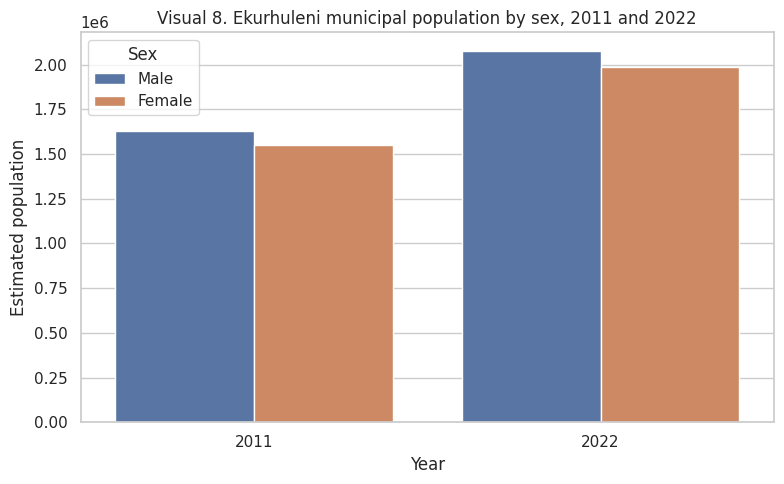

,name,total_pop_2011,female_pop_2011,male_pop_2011,total_pop_2022,female_pop_2022,male_pop_2022,growth_rate_2011_to_2022
52,Ekurhuleni,3178470,1550747,1627724,4066691,1989339,2077352,2.4


In [23]:
pop_eku = population.loc[population['municipality_key'].eq('ekurhuleni')].copy()
if pop_eku.empty:
    print('No Ekurhuleni record found in the population dataset. Check municipality name matching.')
else:
    r = pop_eku.iloc[0]
    pop_plot = pd.DataFrame({
        'Year': ['2011', '2011', '2022', '2022'],
        'Sex': ['Male', 'Female', 'Male', 'Female'],
        'Population': [r['male_pop_2011'], r['female_pop_2011'], r['male_pop_2022'], r['female_pop_2022']]
    })
    plt.figure(figsize=(8, 5))
    sns.barplot(data=pop_plot, x='Year', y='Population', hue='Sex')
    plt.title('Visual 8. Ekurhuleni municipal population by sex, 2011 and 2022')
    plt.ylabel('Estimated population')
    plt.tight_layout()
    plt.show()
    display(pop_eku[['name', 'total_pop_2011', 'female_pop_2011', 'male_pop_2011',
                     'total_pop_2022', 'female_pop_2022', 'male_pop_2022',
                     'growth_rate_2011_to_2022']])

## 20. Pattern analysis — Select three stations for comparison

We select three stations based on the data, rather than choosing them arbitrarily: among stations with at least five non-missing violence observations, we select the stations with the highest hotspot share. If fewer than three meet that condition, we use the available stations with the most observed years. This is a descriptive selection rule and should be reported when interpreting the comparison.

,station_key,station,years_with_violence,mean_violence,median_violence,hotspot_years,hotspot_share
30,tembisa,tembisa,19,1972.526316,1897.0,19.0,1.0
18,ivory park,ivory park,19,1650.894737,1765.0,19.0,1.0
33,tsakane,tsakane,19,1442.947368,1421.0,19.0,1.0


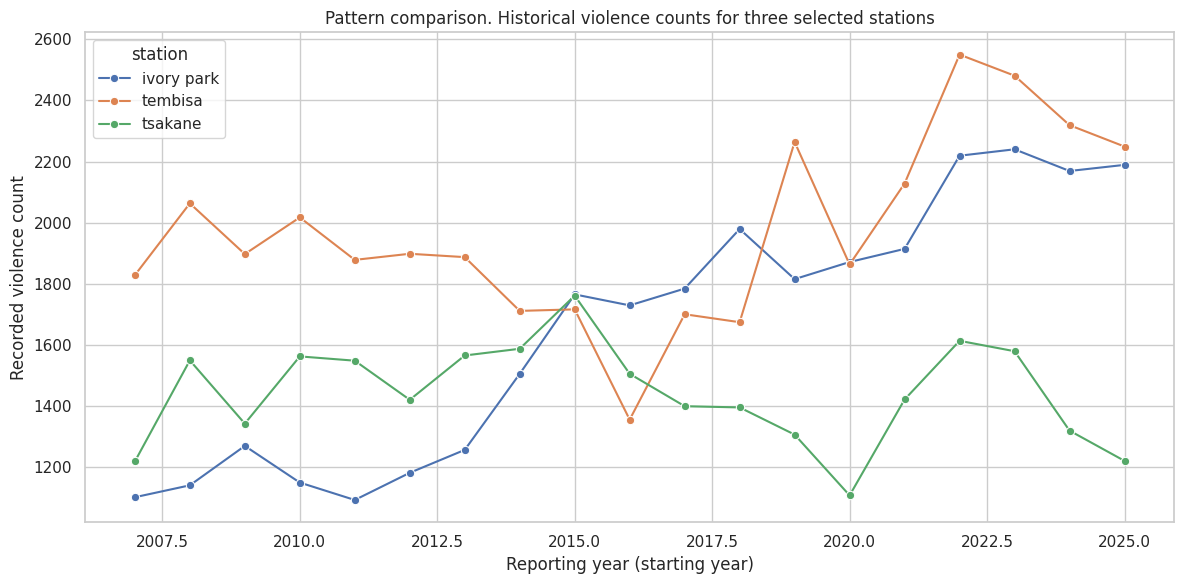

In [24]:
station_patterns = (
    ekurhuleni.groupby(['station_key', 'station'])
    .agg(
        years_with_violence=('violence_count', 'count'),
        mean_violence=('violence_count', 'mean'),
        median_violence=('violence_count', 'median'),
        hotspot_years=('hotspot', 'sum'),
        hotspot_share=('hotspot', 'mean')
    )
    .reset_index()
)

eligible = station_patterns[station_patterns['years_with_violence'] >= 5].copy()
if len(eligible) >= 3:
    selected_three = eligible.sort_values(
        ['hotspot_share', 'mean_violence'], ascending=False
    ).head(3)
else:
    selected_three = station_patterns.sort_values(
        ['years_with_violence', 'mean_violence'], ascending=False
    ).head(3)

display(selected_three)

selected_names = selected_three['station'].tolist()
three_trend = (
    ekurhuleni[ekurhuleni['station'].isin(selected_names)]
    .groupby(['year_start', 'station'])['violence_count']
    .sum(min_count=1)
    .reset_index()
    .dropna(subset=['year_start'])
)

plt.figure(figsize=(12, 6))
sns.lineplot(data=three_trend, x='year_start', y='violence_count', hue='station', marker='o')
plt.xlabel('Reporting year (starting year)')
plt.ylabel('Recorded violence count')
plt.title('Pattern comparison. Historical violence counts for three selected stations')
plt.tight_layout()
plt.show()

## 21. Prepare a leakage-aware classification dataset

**Prediction task:** use the previous observed year’s crime counts at a station to classify whether the current station-year is a hotspot.

**Why lag features?** If we used the current year's crime counts to predict the hotspot label defined from those same counts, the model would simply learn the rule used to create the label. Using previous observed values makes the task closer to a forecast and reduces target leakage.

We use previous-year values for the selected violence categories. The target is only available when the current-year violence components are complete. We keep the year order chronological for splitting.

In [25]:
model_data = ekurhuleni.sort_values(['station_key', 'year_start']).copy()

lag_source_cols = violence_components
for col in lag_source_cols:
    model_data[f'lag1_{col}'] = model_data.groupby('station_key')[col].shift(1)

model_data['lag1_violence_count'] = model_data.groupby('station_key')['violence_count'].shift(1)

feature_cols = [f'lag1_{c}' for c in lag_source_cols] + ['lag1_violence_count']

model_data = model_data.dropna(subset=['year_start', 'hotspot']).copy()
model_data['hotspot'] = model_data['hotspot'].astype(int)

# Keep rows where at least one prior-year feature exists; remaining missing values are imputed inside each model pipeline.
model_data = model_data.loc[model_data[feature_cols].notna().any(axis=1)].copy()

print('Rows available for modelling:', len(model_data))
print('Hotspot class distribution:')
display(model_data['hotspot'].value_counts().rename(index={0: 'Not hotspot', 1: 'Hotspot'}).to_frame('rows'))
print('Unique reporting years available:', sorted(model_data['year_start'].dropna().astype(int).unique()))

Rows available for modelling: 695
Hotspot class distribution:


,rows
hotspot,
Not hotspot,521
Hotspot,174


Unique reporting years available: [np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


## 22. Split by time: 70% train, 15% validation, 15% test

A random row split could put the same station's later years in training and earlier years in testing, which would give an overly optimistic evaluation. Instead, we split distinct years in chronological order. Because the number of years is finite, the realised percentages by rows may differ slightly from 70/15/15; the year periods are kept separate to prevent future years leaking into training.

- **Training set:** fit model parameters.
- **Validation set:** compare the candidate models and select one using F1-score.
- **Test set:** final evaluation only after model selection.

In [26]:
years = np.array(sorted(model_data['year_start'].dropna().astype(int).unique()))
if len(years) < 7:
    raise ValueError(f'Only {len(years)} distinct years are available after lagging; chronological 70/15/15 evaluation may be unreliable.')

n_years = len(years)
train_end = max(1, int(np.floor(n_years * 0.70)))
valid_end = max(train_end + 1, int(np.floor(n_years * 0.85)))
valid_end = min(valid_end, n_years - 1)

train_years = years[:train_end]
valid_years = years[train_end:valid_end]
test_years = years[valid_end:]

train = model_data[model_data['year_start'].isin(train_years)].copy()
valid = model_data[model_data['year_start'].isin(valid_years)].copy()
test = model_data[model_data['year_start'].isin(test_years)].copy()

X_train, y_train = train[feature_cols], train['hotspot']
X_valid, y_valid = valid[feature_cols], valid['hotspot']
X_test, y_test = test[feature_cols], test['hotspot']

print(f'Train years ({len(train_years)}): {train_years}')
print(f'Validation years ({len(valid_years)}): {valid_years}')
print(f'Test years ({len(test_years)}): {test_years}')
print('Rows: train =', len(train), '| validation =', len(valid), '| test =', len(test))
print('Actual row percentages:',
      round(100*len(train)/len(model_data), 1),
      round(100*len(valid)/len(model_data), 1),
      round(100*len(test)/len(model_data), 1))

display(pd.DataFrame({
    'split': ['Train', 'Validation', 'Test'],
    'first_year': [train_years.min(), valid_years.min(), test_years.min()],
    'last_year': [train_years.max(), valid_years.max(), test_years.max()],
    'rows': [len(train), len(valid), len(test)]
}))

Train years (14): [2006 2007 2008 2009 2010 2011 2012 2013 2014 2015 2016 2017 2018 2019]
Validation years (3): [2020 2021 2022]
Test years (3): [2023 2024 2025]
Rows: train = 479 | validation = 108 | test = 108
Actual row percentages: 68.9 15.5 15.5


,split,first_year,last_year,rows
0,Train,2006,2019,479
1,Validation,2020,2022,108
2,Test,2023,2025,108


## 23. Train two models and compare them on validation data

We compare two understandable baseline models:

1. **Logistic Regression:** a simple, interpretable linear classifier. Standardisation helps because predictors are measured on different scales.
2. **Random Forest:** captures non-linear patterns and interactions without requiring a linear relationship.

Both pipelines impute missing predictor values using the training data only. Class weights help address class imbalance. The model with the higher validation F1-score is selected; the test set is not used for model selection.

In [27]:
models = {
    'Logistic Regression': Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE
        ))
    ]),
    'Random Forest': Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('classifier', RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2,
            class_weight='balanced_subsample',
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

validation_results = []
fitted_models = {}

for name, model in models.items():
    if y_train.nunique() < 2:
        raise ValueError('Training split has only one target class. The model cannot learn a binary classifier; inspect the split and hotspot threshold.')
    model.fit(X_train, y_train)
    fitted_models[name] = model
    valid_pred = model.predict(X_valid)
    validation_results.append({
        'model': name,
        'validation_precision': precision_score(y_valid, valid_pred, zero_division=0),
        'validation_recall': recall_score(y_valid, valid_pred, zero_division=0),
        'validation_f1': f1_score(y_valid, valid_pred, zero_division=0),
        'validation_balanced_accuracy': balanced_accuracy_score(y_valid, valid_pred)
    })

validation_results = pd.DataFrame(validation_results).sort_values('validation_f1', ascending=False)
display(validation_results)

best_model_name = validation_results.iloc[0]['model']
best_model = fitted_models[best_model_name]
print('Selected model based on validation F1:', best_model_name)

,model,validation_precision,validation_recall,validation_f1,validation_balanced_accuracy
0,Logistic Regression,0.812500,0.962963,0.881356,0.944444
1,Random Forest,0.833333,0.925926,0.877193,0.932099


Selected model based on validation F1: Logistic Regression


## 24. Final test evaluation

After choosing a model on the validation set, we refit that selected model on the combined training and validation periods, then evaluate once on the untouched test period. We report precision, recall, F1, balanced accuracy, Matthews correlation coefficient (MCC), average precision, and ROC-AUC where both classes are present. No single metric is sufficient when hotspots are a minority class.

In [28]:
# Recreate the selected model configuration and fit on train + validation.
if best_model_name == 'Logistic Regression':
    final_model = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE
        ))
    ])
else:
    final_model = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('classifier', RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2,
            class_weight='balanced_subsample',
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])

X_train_valid = pd.concat([X_train, X_valid], axis=0)
y_train_valid = pd.concat([y_train, y_valid], axis=0)

if y_train_valid.nunique() < 2:
    raise ValueError('Train + validation contain only one class. Cannot fit a binary classifier.')

final_model.fit(X_train_valid, y_train_valid)
test_pred = final_model.predict(X_test)

test_metrics = {
    'model': best_model_name,
    'test_precision': precision_score(y_test, test_pred, zero_division=0),
    'test_recall': recall_score(y_test, test_pred, zero_division=0),
    'test_f1': f1_score(y_test, test_pred, zero_division=0),
    'test_balanced_accuracy': balanced_accuracy_score(y_test, test_pred),
    'test_mcc': matthews_corrcoef(y_test, test_pred)
}

if y_test.nunique() == 2:
    test_metrics['test_roc_auc'] = roc_auc_score(y_test, final_model.predict_proba(X_test)[:, 1])
    test_metrics['test_average_precision'] = average_precision_score(y_test, final_model.predict_proba(X_test)[:, 1])
else:
    test_metrics['test_roc_auc'] = np.nan
    test_metrics['test_average_precision'] = np.nan
    print('Warning: test set contains only one class; ROC-AUC and average precision are not interpretable here.')

display(pd.DataFrame([test_metrics]).T.rename(columns={0: 'value'}))
print('\nClassification report on the test set:')
print(classification_report(y_test, test_pred, target_names=['Not hotspot', 'Hotspot'], zero_division=0))

,value
model,Logistic Regression
test_precision,0.787879
test_recall,0.962963
test_f1,0.866667
test_balanced_accuracy,0.938272
test_mcc,0.823968
test_roc_auc,0.982625
test_average_precision,0.962366



Classification report on the test set:
              precision    recall  f1-score   support

 Not hotspot       0.99      0.91      0.95        81
     Hotspot       0.79      0.96      0.87        27

    accuracy                           0.93       108
   macro avg       0.89      0.94      0.91       108
weighted avg       0.94      0.93      0.93       108



## 25. Visual 9 — Confusion matrix

The confusion matrix counts true negatives, false positives, false negatives, and true positives. False negatives are especially important here because they are hotspot station-years the model failed to flag. False positives indicate station-years the model flagged as hotspots when the reference label was not a hotspot.

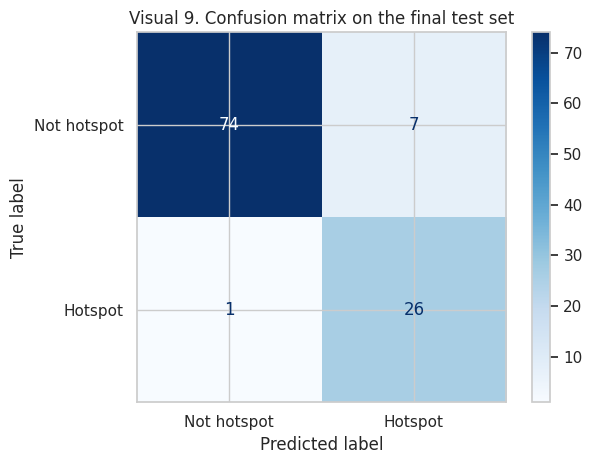

In [29]:
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not hotspot', 'Hotspot'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Visual 9. Confusion matrix on the final test set')
plt.tight_layout()
plt.show()

## 26. Interpret the metrics in plain language

- **Precision:** Of station-years predicted as hotspots, what proportion were labelled hotspots?
- **Recall:** Of actual hotspot station-years, what proportion did the model identify?
- **F1-score:** Harmonic mean of precision and recall; useful when both missed hotspots and false alarms matter.
- **Balanced accuracy:** Average of recall for the hotspot and non-hotspot classes, so the majority class does not dominate the score.
- **MCC:** Correlation between predicted and actual labels; it uses all four confusion-matrix outcomes and is useful with imbalanced classes.
- **Average precision / ROC-AUC:** Ranking metrics based on predicted probabilities. Interpret with caution if the test period has very few positive examples.

The target is a relative 75th-percentile hotspot label, not an official safety designation. Results describe the model's ability to reproduce this operational definition, not whether an area is objectively safe or unsafe.

## 27. Export clean analysis tables

These tables can be saved to Google Drive for later use in the written report or dashboard. The notebook exports the joined Ekurhuleni analysis data, station summary, annual trend, and test metrics. The original downloaded datasets are not overwritten.

In [30]:
DATA_DIR = Path('.')
OUTPUT_DIR = DATA_DIR / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Ensure station_patterns is calculated if cell 7e764233 was skipped
station_patterns = (
    ekurhuleni.groupby(['station_key', 'station'])
    .agg(
        years_with_violence=('violence_count', 'count'),
        mean_violence=('violence_count', 'mean'),
        median_violence=('violence_count', 'median'),
        hotspot_years=('hotspot', 'sum'),
        hotspot_share=('hotspot', 'mean')
    )
    .reset_index()
)

station_summary = station_patterns.sort_values(
    ['hotspot_share', 'mean_violence'], ascending=False
)

ekurhuleni.to_csv(OUTPUT_DIR / 'ekurhuleni_station_year_analysis.csv', index=False)
station_summary.to_csv(OUTPUT_DIR / 'ekurhuleni_station_summary.csv', index=False)
annual_violence.to_csv(OUTPUT_DIR / 'ekurhuleni_annual_violence_trend.csv', index=False)
pd.DataFrame([test_metrics]).to_csv(OUTPUT_DIR / 'hotspot_model_test_metrics.csv', index=False)

print('Saved output files to:', OUTPUT_DIR.resolve())
print([p.name for p in OUTPUT_DIR.iterdir()])

Saved output files to: /content/outputs
['hotspot_model_test_metrics.csv', 'ekurhuleni_station_year_analysis.csv', 'ekurhuleni_annual_violence_trend.csv', 'ekurhuleni_station_summary.csv']


## 28. Limitations and conclusion

### Limitations
1. **Recorded crime is not all crime.** Police statistics reflect crimes reported to and recorded by police.
2. **No station boundary polygons were included.** Geographic analysis uses the SAPS municipality field and station coordinates. A true point-in-polygon boundary match would require a compatible station boundary dataset.
3. **Municipal population is not station-level population.** We use it as background context only; we do not divide station counts by the full Ekurhuleni population.
4. **The hotspot threshold is relative.** A station is labelled a hotspot when its violence count reaches or exceeds the annual 75th percentile. This identifies high-count station-years relative to other stations in the same year.
5. **Missing values and category definitions matter.** Missing crime counts are not assumed to be zero. The violence index excludes the broad `sexual_offences` field to reduce overlap with specific categories.
6. **Temporal coverage and reporting practices may change.** Apparent trends may reflect changes in reporting, classification, or station structures as well as crime patterns.
7. **Model evaluation is time-based.** The latest years are held out for testing, but the number of years is limited. Metrics can be unstable if the test period contains few hotspots.

### Conclusion template
After running the notebook, write a short conclusion based on your actual charts and metrics:
- State which categories and years stand out in the Ekurhuleni data.
- Identify the three stations selected by the stated rule and describe how their trends differ.
- Report the selected model and its test precision, recall, F1, balanced accuracy, and MCC.
- Explain one practical limitation and one way future work could improve the analysis.
Computational Complexity Analysis

Let:

- **n** = number of observations,
- **m** = number of features,
- **T** = number of trees in the Random Forest,
- **k** = number of K-Means clusters,
- **i** = number of K-Means iterations.

### Data cleaning and filtering
Most operations scan the dataset once, giving approximately:

**O(n)**

### Grouping and aggregation
Pandas grouping requires processing the observations and is approximately:

**O(n)** to **O(n log n)** depending on the grouping/sorting operation.

### Random Forest training
A simplified complexity approximation is:

**O(T × n × m × log n)**

because multiple decision trees are constructed and each tree repeatedly searches for useful feature splits.

Prediction is substantially cheaper than training.

### K-Means clustering
K-Means has approximate complexity:

**O(n × k × m × i)**

because every observation is repeatedly compared with the cluster centres until convergence.

### Memory complexity
The main tabular data requires approximately:

**O(n × m)**

memory.

The dataset is therefore computationally manageable because the Ekurhuleni subset contains far fewer observations than the complete national dataset.